In [ ]:
from IPython.display import HTML, display
display(HTML('<style id="notebook-left-alignment">h1,h2,h3,h4,h5,h6,th {text-align:left !important;} .dataframe th {text-align:left !important;}</style>'))

<Notebook heading styles>

<h1 style="text-align: left;">YOLO Tree Counter Evaluation</h1>
**AI First Nations | evidence against the supplied HD specification | 11 October 2026**

<h2 style="text-align: left;">1. Introduction</h2>
This notebook evaluates the saved YOLO11n tree-crown detector and the actual Flask
upload-to-result path. It separates detection quality, counting accuracy, software
correctness and suitability for deployment. A rigorous negative finding is valid;
high model accuracy is not manufactured to obtain an academic grade.

**Current decision: NOT READY for unattended mangrove inventory.** The external
forest benchmark shows poor transfer, the original source has site overlap and
visible annotation-marker risk, and Mourilyan has no reviewed crown labels.
This notebook closes substantial evaluation gaps but does not certify HD compliance
or assign itself a mark. The remaining non-negotiable data gaps are explicit.

Research questions:
1. How accurately are individual crowns located?
2. How closely do counts match reference crown counts?
3. Does accuracy transfer to different sources/sites?
4. How do density, crown size, image degradation and tile boundaries affect results?
5. Does the real Flask pipeline reproduce offline results, and at what runtime/memory cost?

Scope: all visible tree crowns, not confirmed mangrove species or hidden stems.
The 194 NEON images carry published human crown labels. The 970 derived variations
are paired stress tests, not 970 additional independent samples. No test result
is used to select the candidate settings. No weights are retrained or deployed.

Engineering targets from the specification: precision ≥90%, recall ≥85%, mAP50 ≥0.85,
aggregate relative absolute count error ≤10%. These are aspirational operational
targets, not academic cut-offs. Runtime/memory limits have not been agreed.

Specification: `evaluations/specifications/AI_First_Nations_YOLO_Tree_Counter_HD_Evaluation_Specification.pdf`.
The broader all-model notebook overview is deferred in `evaluations/DEFERRED_NOTEBOOK_PLAN.md`.

<h3 style="text-align: left;">Application deployment update — 11 October 2026</h3>
The evaluated candidate is now applied to the application and command-line default:
confidence **0.10**, NMS IoU **0.45**, tile size **640**, overlap **64**.
The saved model weights are unchanged. All **18 actual HTTP acceptance checks passed**
with the deployed settings; see `../tree_counter_hd/deployment_validation/` for
settings, parity checks and measured runtime/memory. The 9 automated tests also passed.

The baseline Flask results below remain historical evidence. The evaluation runner
explicitly restores baseline settings inside its isolated test process to reproduce
those results. Use `flask_validation.py --current` to verify the deployed settings.
The candidate accuracy tables apply to the deployed configuration, with the same
source-data limitations. This deployment does not establish reliable survey accuracy.

Temporary upload copies, duplicate downloaded TIFF sources, browser profiles,
review screenshots and caches were removed. Labels, prepared evaluation images,
notebooks, final results and reproducibility scripts were retained.


<h3 style="text-align: left;">Execution and provenance</h3>
Use the project virtual environment, the existing 91 labelled images, the saved
tree/binary/category checkpoints, and the prepared NEON image pack. The tree
weights must match the checksum recorded below; they are not downloaded or trained.
The scripts are shared, reviewable calculation code rather than duplicated notebook implementations.

Install `evaluations/tree_counter_hd/requirements-lock.txt` in a compatible Python
environment. Then execute this notebook with that kernel. `RUN_EVALUATION=True`
recomputes the experiments and real HTTP tests. Allow several minutes and several
GB of memory; local port 5052 must be free. The existing user server is not changed.

In [1]:
from pathlib import Path
import os, sys, json, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from IPython.display import display as _display, Markdown, HTML, Image as DisplayImage
from bs4 import BeautifulSoup

def left_aligned_table(frame, index=True):
    table = BeautifulSoup(frame.to_html(index=index, justify="left"), "html.parser")
    for cell in table.select("th, td"):
        cell["style"] = "text-align: left;"
    return HTML(str(table))

def display(*objects, **kwargs):
    # Apply the same alignment to every displayed dataframe on future runs.
    return _display(*(left_aligned_table(obj) if isinstance(obj, pd.DataFrame) else obj
                      for obj in objects), **kwargs)


ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'tree-counting-model').exists())
OUT=ROOT/'evaluations/tree_counter_hd'
sys.path.insert(0,str(OUT))
from evaluation import samples, BASELINE, digest
plt.rcParams.update({'figure.figsize':(10,4.5),'font.size':11,'axes.spines.top':False,
                     'axes.spines.right':False,'axes.grid':True,'grid.alpha':.18,'figure.dpi':110})
COLORS={'baseline':'#246b63','candidate':'#d57c30','reference':'#536174'}
RUN_EVALUATION=True
if RUN_EVALUATION:
    for script in ['evaluation.py','challenges.py','marker_diagnostic.py','flask_validation.py']:
        result=subprocess.run([sys.executable,str(OUT/script)],cwd=ROOT,text=True,capture_output=True)
        if result.returncode:
            raise RuntimeError(script+' failed:\n'+result.stdout[-2000:]+result.stderr[-2000:])
        print(script+': completed')
    result=subprocess.run([sys.executable,'-m','unittest','discover','-s','tests','-v'],cwd=ROOT,text=True,capture_output=True)
    (OUT/'automated_tests.txt').write_text(result.stdout+result.stderr)
    assert result.returncode==0, result.stderr

def read(name):return json.loads((OUT/name).read_text())
groups=samples()
summary=read('results_summary.json')
locked=read('locked_settings.json')
env=read('environment.json')
assert env['model_sha256']==digest(ROOT/'tree-counting-model/best_tree_counter.pt')
display(Markdown(f"**Model checksum:** `{env['model_sha256']}`. **Selected candidate:** confidence {locked['candidate']['confidence']:.2f}, NMS IoU {locked['candidate']['iou']:.2f}. The application remains at confidence 0.15."))

evaluation.py: completed


challenges.py: completed


marker_diagnostic.py: completed


flask_validation.py: completed


**Model checksum:** `8e40eb9b2807cc482eabe86c716bc48dca10910ac12fe94ccd3d0cb945813b1a`. **Selected candidate:** confidence 0.10, NMS IoU 0.45. The application remains at confidence 0.15.

<h2 style="text-align: left;">2. Dataset audit and EDA</h2>
One source image is the basic scoring unit. Original images use 640×640 pixels;
NEON images are approximately 400×400 and are padded by the application, not enlarged.
Labels are normalized YOLO boxes converted to pixel coordinates. One box denotes
one visible crown. Published source labels are reference answers, not field-verified
stem inventories or a guarantee of annotation completeness.

NEON provenance: https://github.com/weecology/NeonTreeEvaluation at revision
`96b29d566ca7ea9f604de3e1235c503ab101cb8a`; CC0 license and original TIFF/XML files
are retained in the evaluation pack. Its checksums, label bounds and image pairs
were checked by `prepare_evaluation_pack.py`. The 1,164-file manifest preserves
parent IDs so augmentations are never treated as independent samples.

,images,sites,crowns,min_count,max_count
split,,,,,
external,194,22,6633,1,292
test,9,8,759,7,175
train,64,23,5243,16,253
valid,18,16,1524,22,137


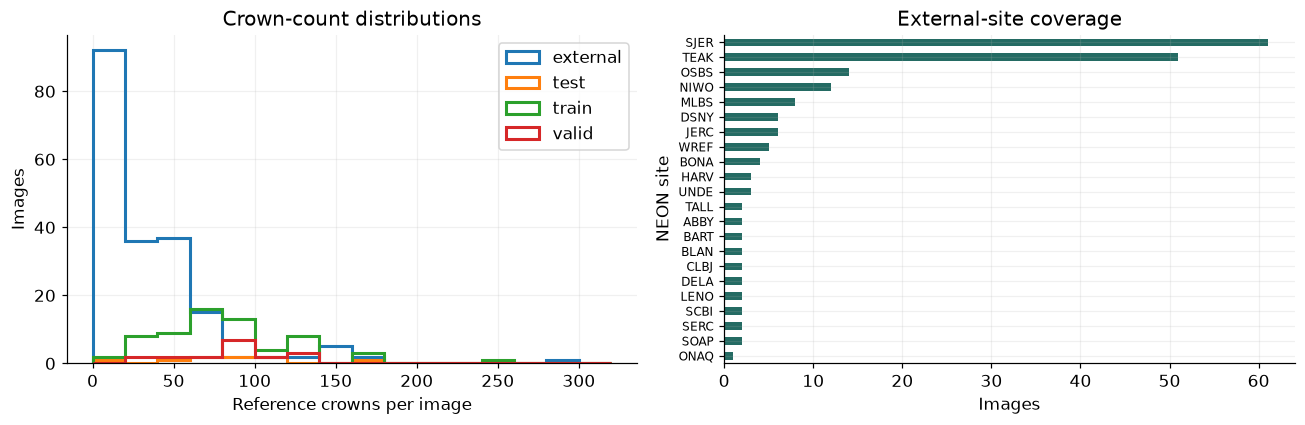

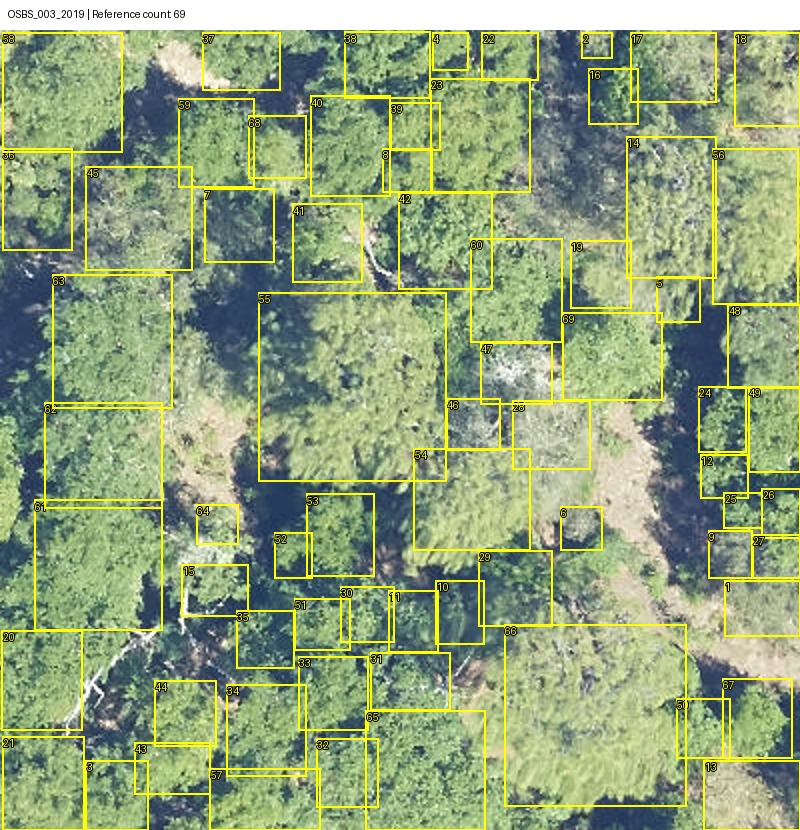

In [2]:
manifest=pd.read_csv(OUT/'split_manifest.csv')
display(manifest.groupby('split').agg(images=('id','size'),sites=('site','nunique'),crowns=('crowns','sum'),min_count=('crowns','min'),max_count=('crowns','max')))
fig,axes=plt.subplots(1,2,figsize=(12,4))
for split,frame in manifest.groupby('split'):
    axes[0].hist(frame.crowns,bins=np.arange(0,321,20),histtype='step',linewidth=2,label=split)
axes[0].set(xlabel='Reference crowns per image',ylabel='Images',title='Crown-count distributions');axes[0].legend()
manifest[manifest.split=='external'].site.value_counts().sort_values().plot.barh(ax=axes[1],color=COLORS['baseline'])
axes[1].set(xlabel='Images',ylabel='NEON site',title='External-site coverage');axes[1].tick_params(axis='y',labelsize=8)
fig.tight_layout();plt.show()
display(DisplayImage(filename=str(ROOT/'tree-counting-model/evaluation_pack/labelled_previews/OSBS_003_2019.jpg'),width=650))

**Interpretation:** counts vary widely, and two NEON sites dominate the external
sample. Dataset size alone does not establish representative coverage. Yellow
boxes above are reference annotations; crowded or overlapping crowns remain an
annotation uncertainty. The scene is general forest, not labelled Mourilyan mangrove imagery.

<h3 style="text-align: left;">Critical source-quality finding: visible annotation markers</h3>
Sampled original training, validation and test photographs contain red cross
markers at tree locations. These are embedded in the source pixels, not added by
our prediction overlays. This creates a possible target-cue shortcut. Section 9
tests a fixed marker-suppression diagnostic on validation only. Authentic clean
source imagery and a reviewed annotation protocol are still required.

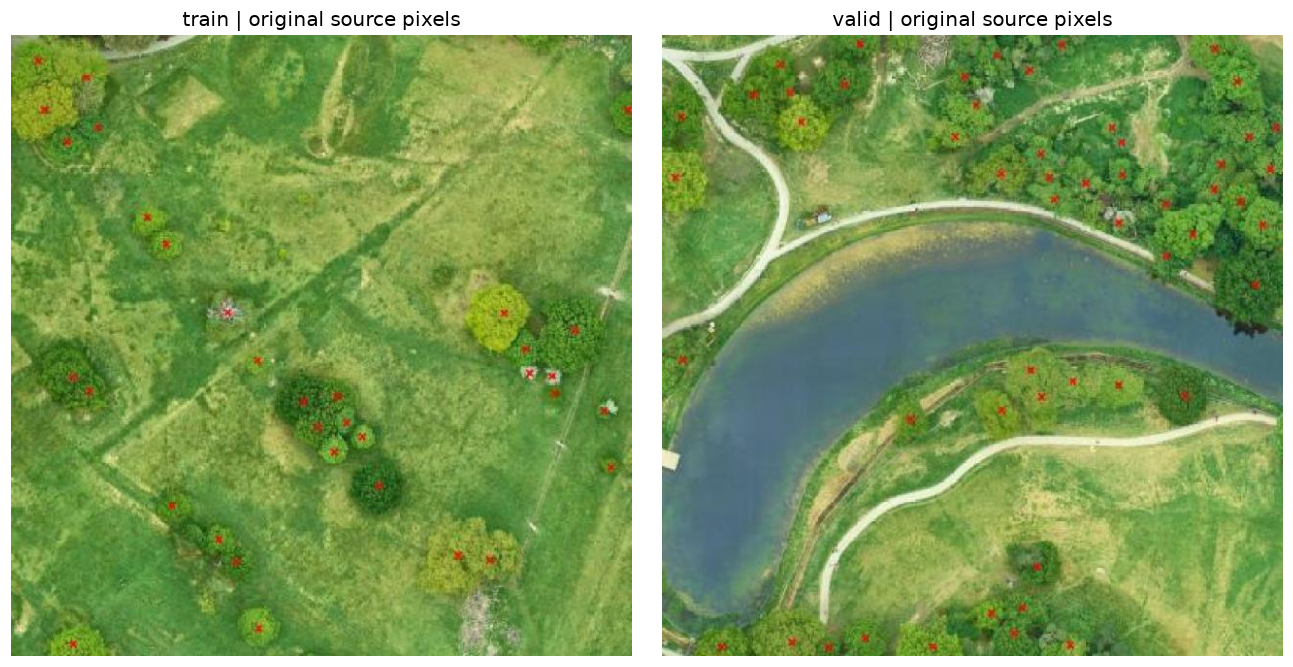

In [3]:
fig,axes=plt.subplots(1,2,figsize=(12,6))
for ax,split in zip(axes,['train','valid']):
    ax.imshow(Image.open(ROOT/groups[split][0]['image']));ax.set_title(split+' | original source pixels');ax.axis('off')
fig.tight_layout();plt.show()

<h2 style="text-align: left;">3. Split integrity</h2>
The historical 64/18/9 split is preserved for comparison, not re-described as an
independent site test. The external source was not used for local training; it has
already been inspected in earlier evaluation, so it is a reused external benchmark,
not a new blind final test. No further threshold selection is performed on it.

In [4]:
audit=read('split_audit.json')
display(pd.DataFrame([{'comparison':k,'shared_prefixes':', '.join(v),'count':len(v)} for k,v in audit['original_site_overlap'].items()]))
old=audit['previous_pack_audit']
display(pd.DataFrame([{'check':'Original duplicate images','observed':old['exact_duplicate_originals']},
 {'check':'Exact matches with existing 91 images','observed':old['exact_matches_existing_dataset']},
 {'check':'Near-match candidates at dHash distance <= 8','observed':len(old['possible_near_duplicates'])}]))

,comparison,shared_prefixes,count
0,train_valid,"bp, cd, hh, hn, is, kg, kn, ng, rc, rp, sc, sg...",16
1,train_test,"bp, bs, cd, cl, cr, el, vp, wm",8


,check,observed
0,Original duplicate images,0
1,Exact matches with existing 91 images,0
2,Near-match candidates at dHash distance <= 8,0


**Interpretation:** all eight original test site prefixes also occur in training.
Exact/near-image screening is useful but does not prove absence of geographic or
pretraining overlap. A clean source/site/date split must be established before
tiling in a future training experiment. This non-negotiable requirement is not
retroactively repaired by renaming a folder or shuffling already related tiles.

<h2 style="text-align: left;">4. Model setup and reproducibility</h2>
YOLO11n, one tree class; saved checkpoint stays frozen. Historical training used
30 epochs, batch 16, image size 640, seed 42 and MPS. The evaluation explicitly uses
CPU on the recorded MacBook hardware, with NumPy/Python/Torch seeds set to 42 and
deterministic Torch operations requested. Cross-device bitwise equality is not assumed.

,Recorded training setting
model,yolo11n.pt
epochs,30
batch,16
imgsz,640
device,mps
seed,42
deterministic,True
hsv_h,0.015
hsv_s,0.7
hsv_v,0.4


,Installed version
torch,2.13.0
torchvision,0.28.0
ultralytics,8.4.131
numpy,2.5.2
Pillow,12.3.0
pandas,3.0.5
matplotlib,3.11.1
pycocotools,2.0.11
Flask,3.1.3
psutil,7.2.2


Hardware:

    Hardware Overview:

      Model Name: MacBook Air
      Model Identifier: Mac17,3
      Model Number: MDHE4X/A
      Chip: Apple M5
      Total Number of Cores: 10 (4 Super and 6 Efficiency)
      Memory: 16 GB
      System Firmware Version: 18000.121.3
      OS Loader Version: 18000.121.3
      


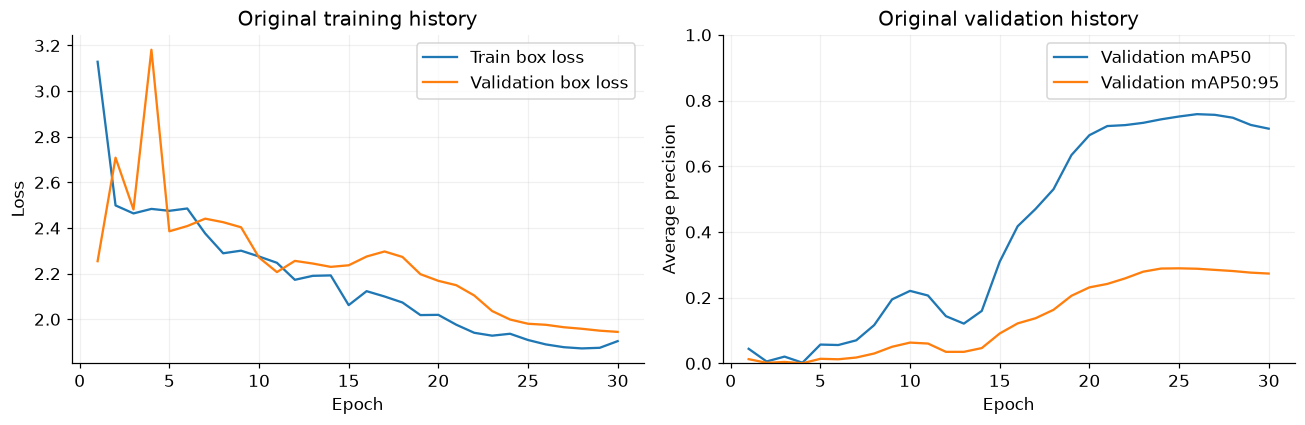

In [5]:
import yaml
training=yaml.safe_load((OUT/'training_history/args.yaml').read_text())
display(pd.Series({k:training.get(k) for k in ['model','epochs','batch','imgsz','device','seed','deterministic','hsv_h','hsv_s','hsv_v','fliplr','mosaic','mixup']},name='Recorded training setting').to_frame())
display(pd.Series(env['packages'],name='Installed version').to_frame())
print(env['hardware'])
history=pd.read_csv(OUT/'training_history/results.csv');history.columns=history.columns.str.strip()
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(history.epoch,history['train/box_loss'],label='Train box loss');axes[0].plot(history.epoch,history['val/box_loss'],label='Validation box loss')
axes[0].set(xlabel='Epoch',ylabel='Loss',title='Original training history');axes[0].legend()
axes[1].plot(history.epoch,history['metrics/mAP50(B)'],label='Validation mAP50');axes[1].plot(history.epoch,history['metrics/mAP50-95(B)'],label='Validation mAP50:95')
axes[1].set(xlabel='Epoch',ylabel='Average precision',title='Original validation history',ylim=(0,1));axes[1].legend()
fig.tight_layout();plt.show()

**Interpretation:** these curves describe the original training run; they do not
establish performance on clean mangrove photographs. The possible marker shortcut
and source overlap apply to those validation curves too. Complete augmentation
and optimizer settings are retained in `training_history/args.yaml`.

<h2 style="text-align: left;">5. Detection evaluation</h2>
Operating precision/recall/F1 use one-to-one matching at IoU 0.50. AP is computed
with the official `pycocotools` evaluator: 101 recall positions, IoUs 0.50–0.95,
one class, all object sizes, **maxDets=300**, low confidence floor 0.001. This is
explicitly an AP@300 configuration, not the COCO default AP@100. Very low-score
predictions below 0.001 are not included. The original image coordinate boxes
come from the same tiling/restoration/NMS code as the application.

AP source: https://github.com/cocodataset/cocoapi/blob/master/PythonAPI/pycocotools/cocoeval.py

,images,precision,recall,f1,map50,map50_95
baseline_test,9.0,0.9126,0.6877,0.7844,0.7950,0.3139
baseline_external,194.0,0.4468,0.0063,0.0125,0.0469,0.0140
candidate_test,9.0,0.8778,0.7760,0.8238,0.7950,0.3139
candidate_external,194.0,0.3640,0.0155,0.0298,0.0469,0.0140


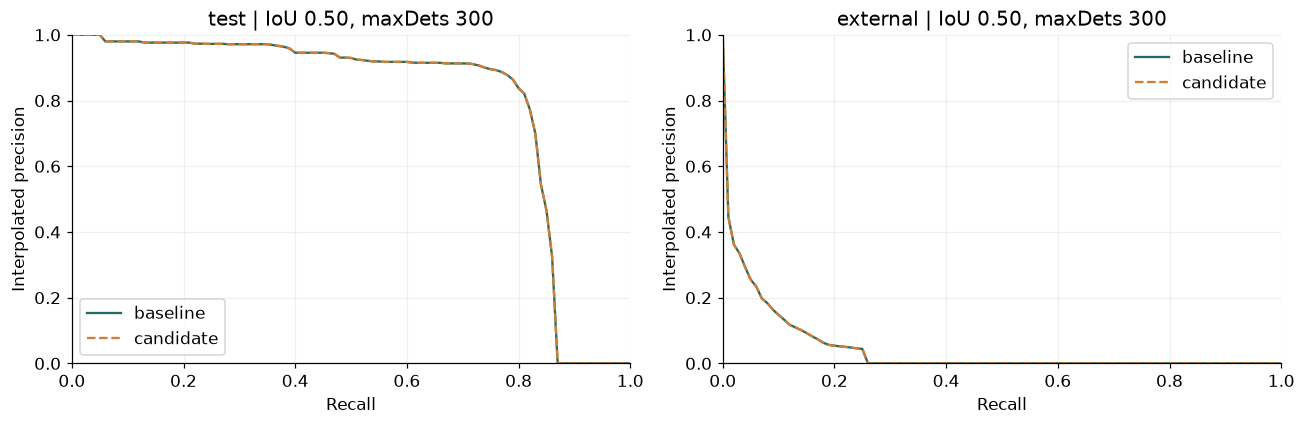

In [6]:
metrics=pd.DataFrame(summary).T
display(metrics[['images','precision','recall','f1','map50','map50_95']].round(4))
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,split in zip(axes,['test','external']):
    for mode in ['baseline','candidate']:
        pr=read(mode+'_'+split+'/precision_recall.json')
        ax.plot(pr['recall_axis'],pr['precision_curve_iou50'],label=mode,color=COLORS[mode],linestyle='-' if mode=='baseline' else '--')
    ax.set(xlabel='Recall',ylabel='Interpolated precision',title=split+' | IoU 0.50, maxDets 300',xlim=(0,1),ylim=(0,1));ax.legend()
fig.tight_layout();plt.show()

**Interpretation:** external detection performance is much poorer than the original
source. Baseline and candidate AP curves coincide because only the operating
confidence cutoff changed; both AP calculations use the same low-score ranked
detections. A different operating threshold changes precision/recall/counts,
not the underlying ranking. Do not compare these numbers directly with older
Ultralytics notebook values obtained with different postprocessing defaults.

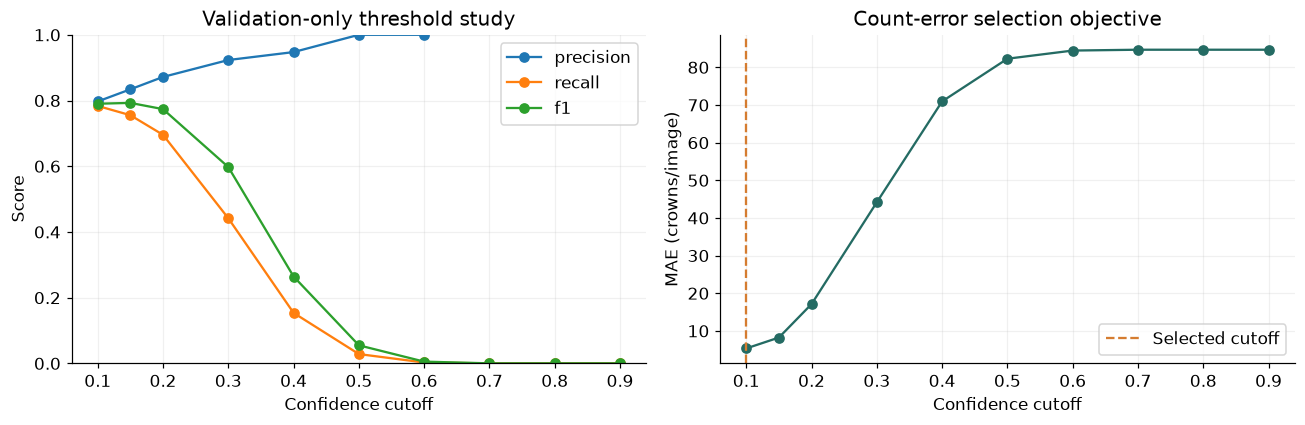

In [7]:
experiments=pd.read_csv(OUT/'validation_experiments.csv')
sweep=experiments[np.isclose(experiments.iou,.45)].sort_values('confidence')
fig,axes=plt.subplots(1,2,figsize=(12,4))
for metric in ['precision','recall','f1']:axes[0].plot(sweep.confidence,sweep[metric],marker='o',label=metric)
axes[0].set(xlabel='Confidence cutoff',ylabel='Score',title='Validation-only threshold study',ylim=(0,1));axes[0].legend()
axes[1].plot(sweep.confidence,sweep.mae,marker='o',color=COLORS['baseline']);axes[1].axvline(locked['candidate']['confidence'],linestyle='--',color=COLORS['candidate'],label='Selected cutoff')
axes[1].set(xlabel='Confidence cutoff',ylabel='MAE (crowns/image)',title='Count-error selection objective');axes[1].legend()
fig.tight_layout();plt.show()

**Interpretation:** threshold selection minimises validation count MAE, not test
error or the aspirational precision target. The saved candidate grid and tie-break
rule precede the new test runs. Validation source overlap/marker risk still limits
how well the chosen cutoff can transfer to clean new imagery.

<h2 style="text-align: left;">6. Counting evaluation</h2>
MAE, RMSE and signed bias are calculated per source image. Aggregate relative
absolute count error is `sum(abs(predicted-reference))/sum(reference)`. Zero-tree
images contribute false-positive errors to its numerator when mixed with positive
images; if the entire reference total is zero, relative error is undefined (`null`),
and absolute errors and false positives are reported instead. Site totals below
sum image annotations; they are not counts of unique trees across overlapping surveys.

,expected,predicted,mae,rmse,bias,relative_absolute_error
baseline_test,759.0,572.0,20.7778,28.3804,-20.7778,0.2464
baseline_external,6633.0,94.0,33.7062,52.0160,-33.7062,0.9858
candidate_test,759.0,671.0,11.1111,16.4181,-9.7778,0.1318
candidate_external,6633.0,283.0,32.7732,51.1332,-32.7320,0.9585


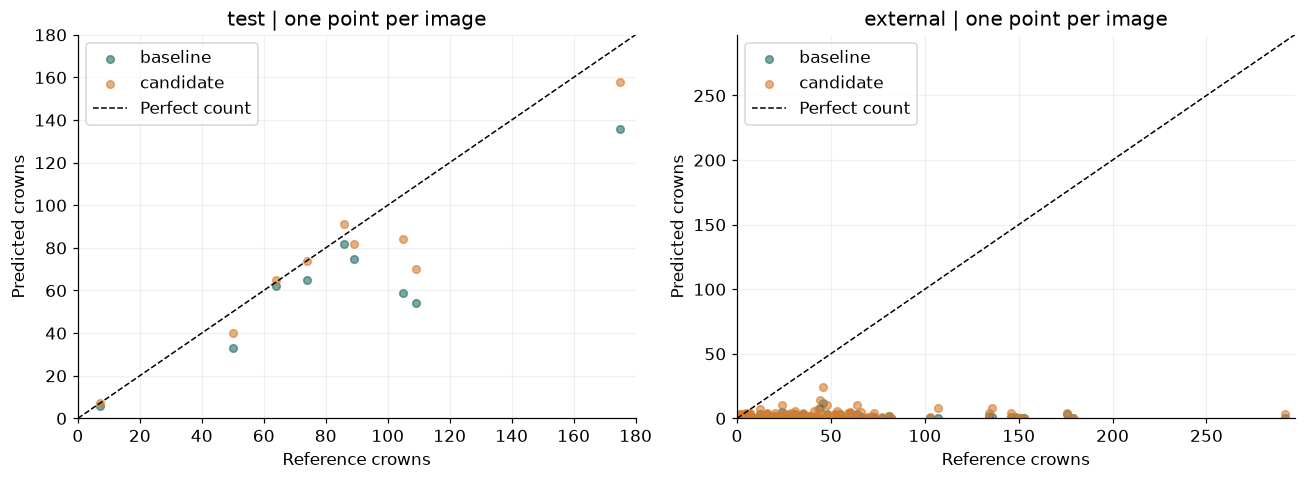

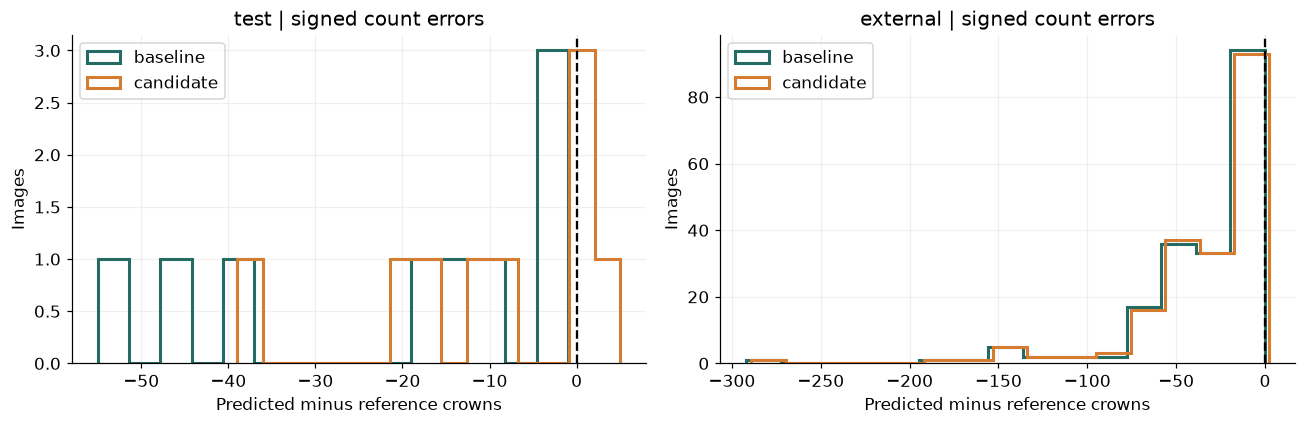

,id,expected,predicted,error
103,NIWO_002_2018,292,3,-289
109,NIWO_014_2018,179,0,-179
102,NIWO_001_2018,176,4,-172
107,NIWO_011_2018,153,0,-153
112,NIWO_017_2018,151,0,-151
110,NIWO_015_2018,150,0,-150
106,NIWO_010_2018,148,1,-147
105,NIWO_005_2018,146,4,-142


In [8]:
display(metrics[['expected','predicted','mae','rmse','bias','relative_absolute_error']].round(4))
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for ax,split in zip(axes,['test','external']):
    for mode in ['baseline','candidate']:
        frame=pd.read_csv(OUT/(mode+'_'+split)/'per_image.csv')
        ax.scatter(frame.expected,frame.predicted,alpha=.6,s=25,label=mode,color=COLORS[mode])
    limit=max(frame.expected.max(),frame.predicted.max())+5
    ax.plot([0,limit],[0,limit],'k--',linewidth=1,label='Perfect count')
    ax.set(xlabel='Reference crowns',ylabel='Predicted crowns',title=split+' | one point per image',xlim=(0,limit),ylim=(0,limit));ax.legend()
fig.tight_layout();plt.show()
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,split in zip(axes,['test','external']):
    for mode in ['baseline','candidate']:
        frame=pd.read_csv(OUT/(mode+'_'+split)/'per_image.csv');ax.hist(frame.error,bins=15,histtype='step',linewidth=2,label=mode,color=COLORS[mode])
    ax.axvline(0,color='black',linestyle='--');ax.set(xlabel='Predicted minus reference crowns',ylabel='Images',title=split+' | signed count errors');ax.legend()
fig.tight_layout();plt.show()
frame=pd.read_csv(OUT/'candidate_external/per_image.csv');frame['absolute_error']=frame.error.abs()
display(frame.sort_values('absolute_error',ascending=False)[['id','expected','predicted','error']].head(8))

**Interpretation:** the selected cutoff reduces original-source count errors but
does not resolve external undercounting. The diagonal gives the correct-count
reference. Count agreement alone would not establish correct tree localisation;
the detection table must be read alongside these plots.

In [9]:
# Site-cluster bootstrap: retain within-site correlation, 2,000 resamples.
rng=np.random.default_rng(42)
f=pd.read_csv(OUT/'candidate_external/per_image.csv')
clusters=[g.error.abs().to_numpy() for _,g in f.groupby('site')]
boot=[]
for _ in range(2000):
    chosen=[clusters[i] for i in rng.integers(0,len(clusters),len(clusters))]
    boot.append(np.concatenate(chosen).mean())
interval=np.quantile(boot,[.025,.975])
display(Markdown(f"Candidate external MAE: **{f.error.abs().mean():.2f}**; exploratory 95% site-cluster bootstrap interval **[{interval[0]:.2f}, {interval[1]:.2f}]** crowns/image."))
display(pd.read_csv(OUT/'candidate_external/site_image_totals_not_survey_counts.csv').head(8))

Candidate external MAE: **32.77**; exploratory 95% site-cluster bootstrap interval **[17.83, 69.42]** crowns/image.

,site,images,image_crown_total,predicted_image_total,bias
0,ABBY,2,160,1,-79.500000
1,BART,2,93,0,-46.500000
2,BLAN,2,72,0,-36.000000
3,BONA,4,255,1,-63.500000
4,CLBJ,2,116,13,-51.500000
5,DELA,2,87,1,-43.000000
6,DSNY,6,87,31,-9.333333
7,HARV,3,171,9,-54.000000


The interval reflects resampling the observed sites, not uncertainty across all
possible forests or Mourilyan surveys. Valid unique-tree survey totals are unavailable:
there is no crown-level cross-image geospatial reconciliation. Per-tile diagnostic
counts are exported separately and must not be summed across overlapping tiles.

<h2 style="text-align: left;">7. Tiling and deduplication</h2>
The same 640×640 tiler is tested on small, exact, off-by-one, large and full-resolution
drone dimensions with overlaps 0/64/128. Three 1280×1280 photographic composites
translate published boxes exactly and exercise real-model boundary handling. They
are artificial joins from historical test images, not additional independent surveys.

,size,overlap,tiles,uncovered_pixels,fixed_640
0,"(200, 180)",0,1,0,True
1,"(200, 180)",64,1,0,True
2,"(200, 180)",128,1,0,True
3,"(640, 640)",0,1,0,True
4,"(640, 640)",64,1,0,True
5,"(640, 640)",128,1,0,True
6,"(641, 641)",0,4,0,True
7,"(641, 641)",64,4,0,True
8,"(641, 641)",128,4,0,True
9,"(1200, 800)",0,4,0,True


,id,overlap,expected,predicted,raw_count,removed,tiles
0,composite_00,0,195,166,166,0,4
1,composite_01,0,313,284,284,0,4
2,composite_02,0,478,324,324,0,4
3,composite_00,64,195,170,454,284,9
4,composite_01,64,313,288,644,356,9
5,composite_02,64,478,333,805,472,9
6,composite_00,128,195,171,452,281,9
7,composite_01,128,313,288,630,342,9
8,composite_02,128,478,333,766,433,9


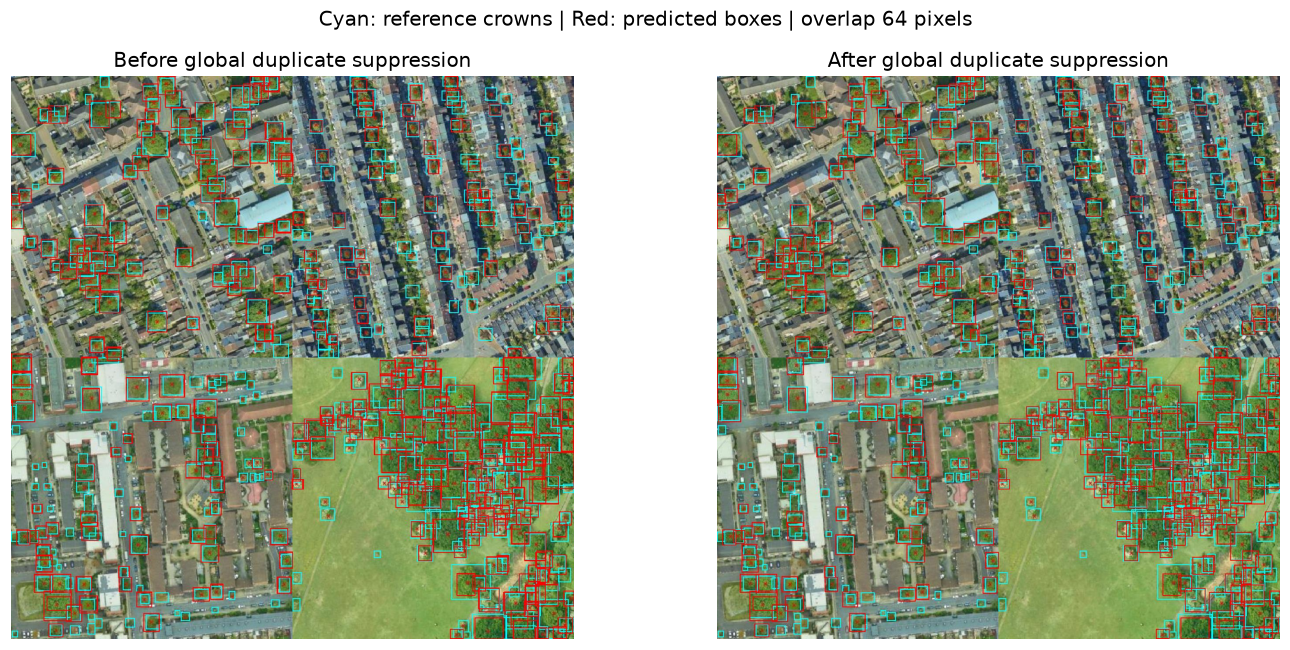

test_empty_predictions_and_labels (test_evaluation_pack.EvaluationPackTests.test_empty_predictions_and_labels) ... ok
test_multiple_predictions_cannot_match_same_tree (test_evaluation_pack.EvaluationPackTests.test_multiple_predictions_cannot_match_same_tree) ... ok
test_transformed_box_follows_pixels_on_non_square_image (test_evaluation_pack.EvaluationPackTests.test_transformed_box_follows_pixels_on_non_square_image) ... ok
test_unmatched_prediction_and_missed_tree_are_both_counted (test_evaluation_pack.EvaluationPackTests.test_unmatched_prediction_and_missed_tree_are_both_counted) ... ok
test_empty_truth_relative_error_is_undefined_not_zero (test_hd_metrics.HDMetricTests.test_empty_truth_relative_error_is_undefined_not_zero) ... ok
test_nonoverlapping_detection_has_zero_ap (test_hd_metrics.HDMetricTests.test_nonoverlapping_detection_has_zero_ap) ... ok
test_perfect_detection_has_perfect_ap (test_hd_metrics.HDMetricTests.test_perfect_detection_has_perfect_ap) ... ok
test_count_uses_sha

In [10]:
display(pd.read_csv(OUT/'tiler_coverage.csv'))
display(pd.read_csv(OUT/'overlap_experiment.csv'))
fig,axes=plt.subplots(1,2,figsize=(13,6))
for ax,suffix,title in zip(axes,['before','after'],['Before global duplicate suppression','After global duplicate suppression']):
    ax.imshow(Image.open(OUT/('composite_02_'+suffix+'_dedup.jpg')));ax.set_title(title);ax.axis('off')
fig.suptitle('Cyan: reference crowns | Red: predicted boxes | overlap 64 pixels');fig.tight_layout();plt.show()
print((OUT/'automated_tests.txt').read_text()[-1800:])

**Interpretation:** coverage checks establish that no source pixels are omitted.
Overlapping tiles can increase raw detections; global suppression removes some
duplicates. Composite counts still reflect missed crowns and imperfect merging.
Coordinate and duplicate-removal fixtures test the software, while these composites
test its behaviour on photographic content. Neither substitutes for annotated full
Mourilyan scenes, and a single tree split across tile edges can still be missed.

<h2 style="text-align: left;">8. Robustness and error analysis</h2>
Stratify only on information actually available. Density is the reference count
per image, not crowns/hectare. Crown-size bins use pixel box area; different source
resolutions mean they are not biological size categories. Shadows, water and
non-mangrove vegetation do not have reviewed condition labels, so no fabricated
condition-specific accuracy is presented.

,images,mae,bias
density,,,
1–20,95,7.400000,-7.400000
21–60,73,41.123288,-41.123288
61+,26,109.000000,-109.000000


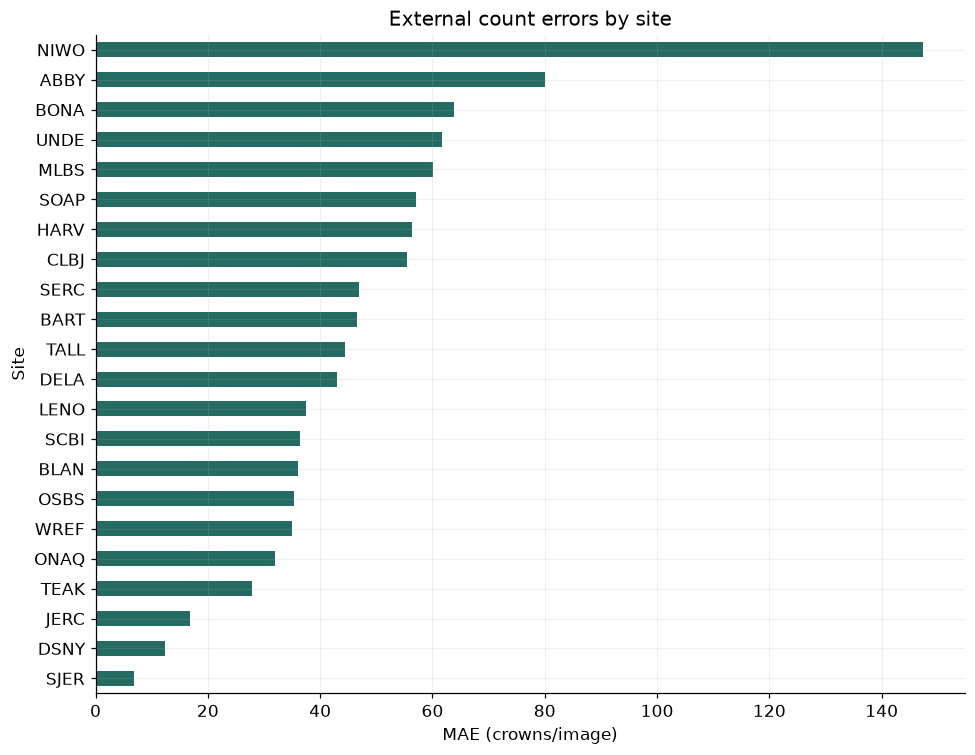

,images,mae,precision_iou50,recall_iou50
blur,194,34.056701,0.461538,0.001809
darker,194,31.015464,0.410714,0.038143
flip_horizontal,194,33.829897,0.423077,0.004975
low_resolution,194,33.927835,0.352941,0.002714
original,194,33.706186,0.446809,0.006332
rotate_90,194,33.907216,0.418182,0.003468


In [11]:
frame=pd.read_csv(OUT/'baseline_external/per_image.csv')
frame['density']=pd.cut(frame.expected,[0,20,60,np.inf],labels=['1–20','21–60','61+'])
frame['abs_error']=frame.error.abs()
display(frame.groupby('density',observed=True).agg(images=('id','size'),mae=('abs_error','mean'),bias=('error','mean')))
site=frame.groupby('site').agg(images=('id','size'),mae=('abs_error','mean')).sort_values('mae')
ax=site.mae.plot.barh(figsize=(9,7),color=COLORS['baseline']);ax.set(xlabel='MAE (crowns/image)',ylabel='Site',title='External count errors by site');plt.tight_layout();plt.show()
# Paired stress tests from the previous same-checkpoint benchmark.
stress=json.loads((ROOT/'tree-counting-model/evaluation_pack/results/summary.json').read_text())
assert stress['model_sha256']==env['model_sha256']
display(pd.DataFrame(stress['by_variant']).T[['images','mae','precision_iou50','recall_iou50']].round(4))

**Interpretation:** larger image counts leave more opportunities for absolute
misses. Site means have uneven sample sizes and confound tree appearance, scale
and density. The paired stress table is the saved same-checkpoint experiment
(194 images per condition), not 1,164 independent tests. Darkening changed
responses but did not establish readiness or justify tuning on these test images.

,reference_crowns,recall
size,,
large ≥96²,123,0.000000
medium 32²–96²,3187,0.006275
small <32²,3323,0.006621


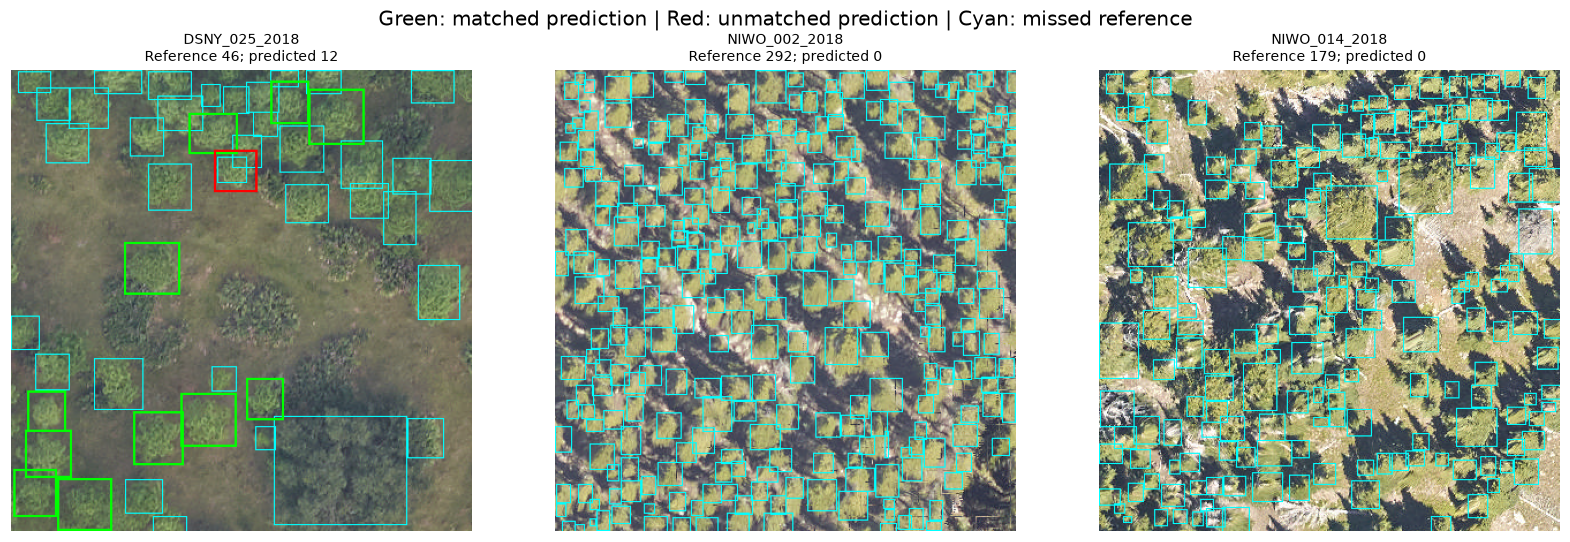

In [12]:
from tree_counter import _box_iou
preds=read('baseline_external/predictions.json')
sizes=[];matched_by_id={}
for sample,pred in zip(groups['external'],preds):
    gt=np.array(sample['boxes']).reshape(-1,4);used=set();matches=[]
    for b in sorted(pred['boxes'],key=lambda b:b[4],reverse=True):
        overlaps=_box_iou(np.array(b[:4]),gt)
        possible=[i for i in range(len(gt)) if i not in used and overlaps[i]>=.5]
        if possible:
            k=max(possible,key=lambda i:overlaps[i]);used.add(k);matches.append((b,k))
        else:matches.append((b,None))
    matched_by_id[sample['id']]=(used,matches)
    for i,b in enumerate(gt):
        area=(b[2]-b[0])*(b[3]-b[1]);sizes.append({'size':'small <32²' if area<32**2 else 'medium 32²–96²' if area<96**2 else 'large ≥96²','found':i in used})
display(pd.DataFrame(sizes).groupby('size').agg(reference_crowns=('found','size'),recall=('found','mean')))
# Show a detected scene and two heavily missed scenes, chosen transparently.
indices=[max(range(len(preds)),key=lambda i:len(preds[i]['boxes']))]+sorted(range(len(preds)),key=lambda i:preds[i]['expected']-preds[i]['predicted'],reverse=True)[:2]
fig,axes=plt.subplots(1,3,figsize=(15,5))
for ax,i in zip(axes,indices):
    sample=groups['external'][i];pred=preds[i];im=Image.open(ROOT/sample['image']).convert('RGB');d=ImageDraw.Draw(im)
    used,matches=matched_by_id[sample['id']]
    for k,b in enumerate(sample['boxes']):
        if k not in used:d.rectangle(b,outline='cyan',width=1)
    for b,k in matches:d.rectangle(b[:4],outline='lime' if k is not None else 'red',width=2)
    ax.imshow(im);ax.axis('off');ax.set_title(f"{sample['id']}\nReference {len(sample['boxes'])}; predicted {len(pred['boxes'])}",fontsize=9)
fig.suptitle('Green: matched prediction | Red: unmatched prediction | Cyan: missed reference');fig.tight_layout();plt.show()

**Interpretation:** the overlays show missed crowns and poorly matched boxes,
including crowded and small-crown scenes. Examples are deliberately selected
for diagnostic value and are not a random performance sample. Pixel area alone
does not identify biological crown size or prove a particular failure cause.

,0
images,12
expected,0
predicted,0
tp,0
fp,0
fn,0
precision,None
recall,None
f1,None
mae,0.0


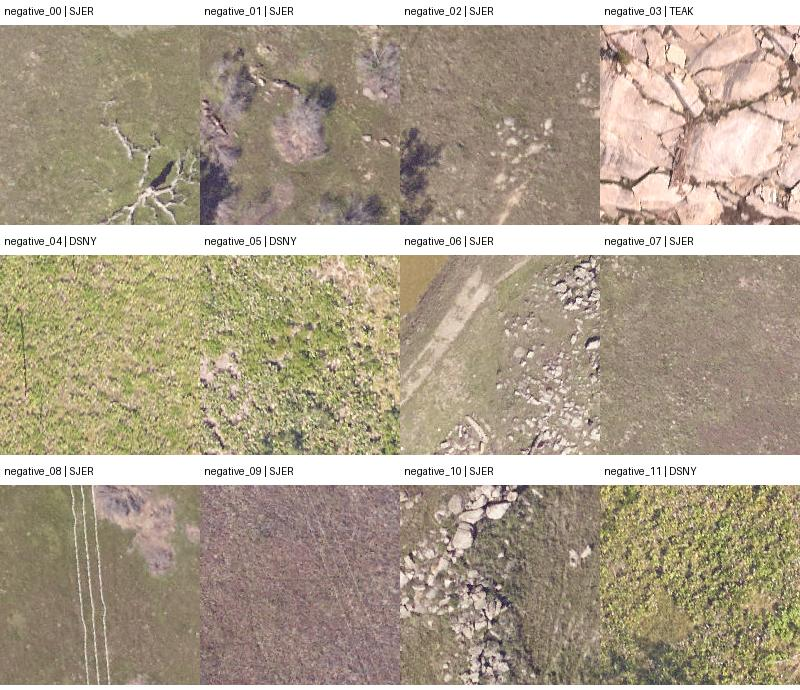

In [13]:
display(pd.DataFrame([read('negative_metrics.json')]).T)
display(DisplayImage(filename=str(OUT/'negative_review.jpg'),width=850))

**Negative-scene interpretation:** these 12 crops intersect no published crown
boxes. Visual review found ground/rock/low vegetation and fallen branches without
obvious standing crowns. Review was by an AI assistant, not an independent human
expert. They are derived, small regions; successful results do not establish
false-positive rates on whole new surveys. Relative error is intentionally
undefined when every reference count is zero.

<h2 style="text-align: left;">9. Controlled improvement experiments</h2>
Experiment A varies only confidence. Experiment B varies only NMS IoU at the
baseline confidence. Both use the original 18 validation images, and the candidate
is frozen before the subsequent test runs. No retraining or test-set optimisation
is performed. A third, validation-only diagnostic examines embedded red markers;
its results do not change the locked candidate.

,confidence,iou,precision,recall,f1,mae,bias
0,0.10,0.45,0.7971,0.7835,0.7902,5.3333,-1.4444
1,0.15,0.45,0.8341,0.7552,0.7927,8.2222,-8.0000
2,0.20,0.45,0.8717,0.6955,0.7737,17.1111,-17.1111
3,0.30,0.45,0.9232,0.4416,0.5974,44.1667,-44.1667
4,0.40,0.45,0.9474,0.1535,0.2643,70.9444,-70.9444
5,0.50,0.45,1.0000,0.0282,0.0549,82.2778,-82.2778
6,0.60,0.45,1.0000,0.0026,0.0052,84.4444,-84.4444
7,0.70,0.45,NaN,0.0000,0.0000,84.6667,-84.6667
8,0.80,0.45,NaN,0.0000,0.0000,84.6667,-84.6667
9,0.90,0.45,NaN,0.0000,0.0000,84.6667,-84.6667


,expected,predicted,precision,recall,mae
original,1524.0,1380.0,0.8341,0.7552,8.2222
red_regions_inpainted,1524.0,851.0,0.8437,0.4711,37.3889


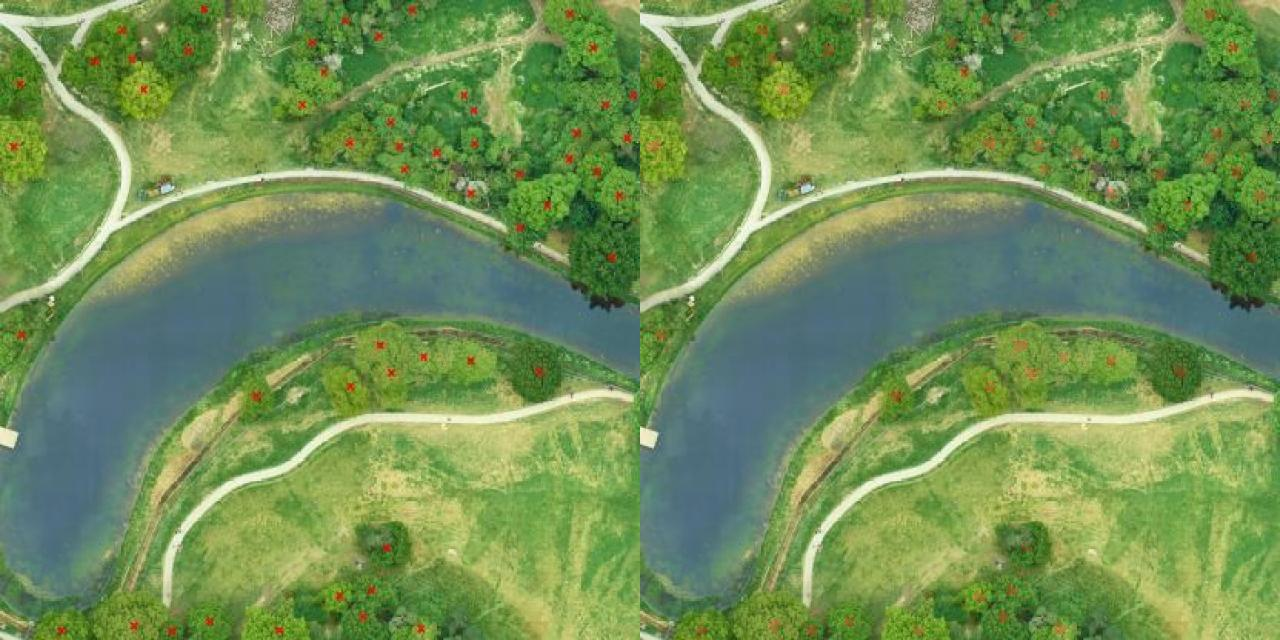

In [14]:
display(experiments[['confidence','iou','precision','recall','f1','mae','bias']].round(4))
marker=read('marker_diagnostic/metrics.json')
display(pd.DataFrame({k:marker[k] for k in ['original','red_regions_inpainted']}).T[['expected','predicted','precision','recall','mae']].round(4))
display(DisplayImage(filename=str(OUT/'marker_diagnostic/before_after.jpg'),width=1100))

**Interpretation:** read improvements together with precision/recall trade-offs.
The marker diagnostic removes small red regions using a fixed colour/component
rule and inpainting. Any performance change is evidence of sensitivity to that
intervention; it does not prove all red regions were annotations or recover the
authentic unmarked photograph. It is not a new ground-truth test set. The original
source pixels and weights remain unchanged. Source marker contamination must be
resolved before using the original benchmark to claim deployment accuracy.

<h2 style="text-align: left;">10. Application integration</h2>
Actual local HTTP requests exercise Flask's upload validation, preprocessing,
all loaded models, tree inference, image-coordinate restoration, deduplication,
overlay creation and rendered count. Reference calls use the same checkpoint and
baseline settings. Count equality is exact; overlay equality uses byte checksums
plus source dimensions. Error tests include unsupported/corrupt/oversized input,
missing upload, unavailable tree weights, and a forced inference exception.

,test,status
0,Checkpoint startup without training/download,PASS
1,neon upload #1: count and overlay parity,PASS
2,neon upload #2: count and overlay parity,PASS
3,neon upload #3: count and overlay parity,PASS
4,original upload #1: count and overlay parity,PASS
5,original upload #2: count and overlay parity,PASS
6,original upload #3: count and overlay parity,PASS
7,composite upload #1: count and overlay parity,PASS
8,composite upload #2: count and overlay parity,PASS
9,composite upload #3: count and overlay parity,PASS


,,,requests,median_seconds,max_seconds,max_process_rss_mb
kind,width,height,,,,
composite,1280,1280,3,0.662,0.680,1209.859
fresh_drone,4032,3024,1,21.686,21.686,2079.953
neon,400,400,3,0.201,0.217,598.422
original,640,640,3,0.380,0.382,661.234


**18/18 acceptance checks passed.** Model-load startup: 1.23 seconds.

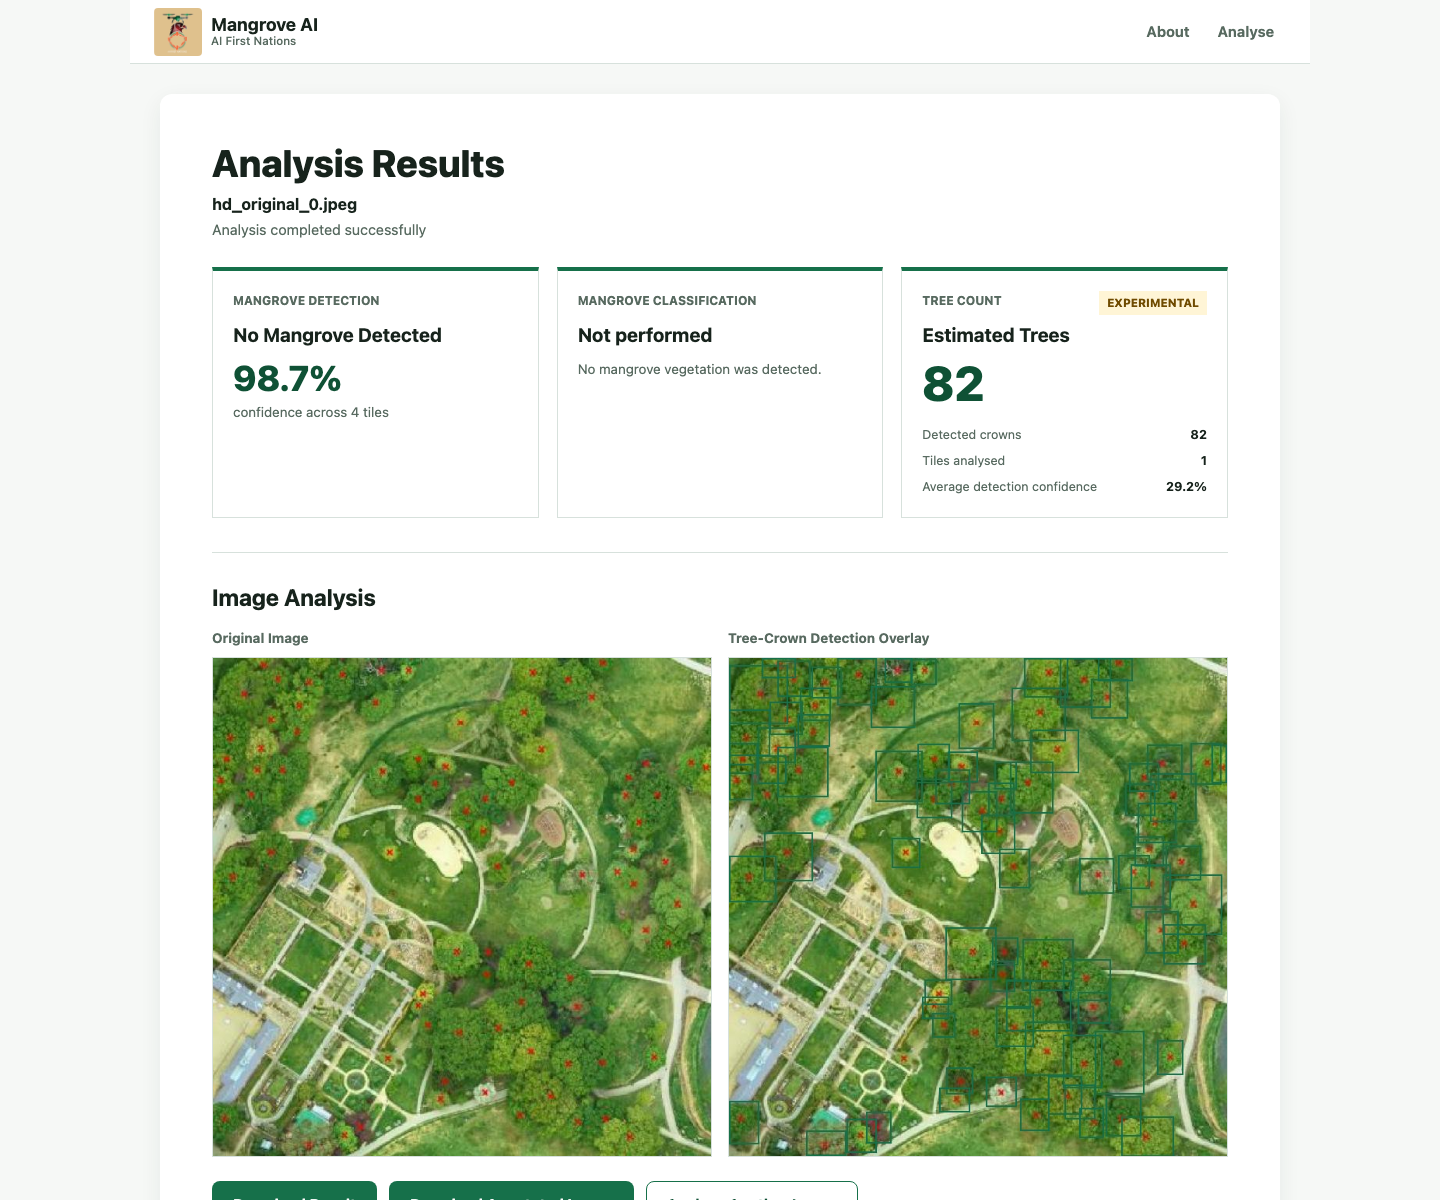

In [15]:
acceptance=pd.read_csv(OUT/'flask_acceptance.csv')
display(acceptance[['test','status']])
latency=pd.read_csv(OUT/'flask_latency_memory.csv')
display(latency.groupby(['kind','width','height']).agg(requests=('seconds','size'),median_seconds=('seconds','median'),max_seconds=('seconds','max'),max_process_rss_mb=('process_peak_rss_mb','max')).round(3))
flask=read('flask_summary.json')
display(Markdown(f"**{flask['passed']}/{flask['tests']} acceptance checks passed.** Model-load startup: {flask['startup_seconds']:.2f} seconds."))
display(DisplayImage(filename=str(OUT/'flask_result.png'),width=1000))

**Interpretation:** the screenshot is an observed Flask result, supported by the
automated pass/fail table, not a mock UI. It shows the baseline app, not deployment
of the candidate cutoff. Timing includes upload through response rendering on
localhost with all three models enabled, after direct parity inference warms the
model. Fresh full-resolution inference has only one timed sample. Model startup
is separate. Process RSS is sampled every 10 ms; it includes model weights and
allocator cache and may miss brief peaks. These are measurements, not guaranteed
latency/memory service levels. No hardware-specific acceptance limit is agreed.

The fresh Mourilyan image has no verified labels: its count is a functionality
example only. Unavailable weights are simulated by an isolated path override;
the user's weight file is not moved. A first exploratory run discovered an image
dependency (`pi-heif`); it is now pinned, and auto-install is disabled for reruns.

<h2 style="text-align: left;">11. Conclusion and specification checklist</h2>
The final comparison below identifies each dataset and procedure. The candidate
means validation-selected **settings on the same frozen weights**, not a newly
trained model. The application remains unchanged at the baseline configuration.

In [16]:
for split,title in [('test','Historical original-source test (9 images; site/marker caveats)'),('external','Reused external NEON benchmark (194 images)')]:
    display(Markdown('### '+title))
    keys=['precision','recall','f1','map50','map50_95','mae','rmse','bias','relative_absolute_error']
    table=pd.DataFrame({'Baseline':[summary['baseline_'+split][k] for k in keys],
                        'Candidate':[summary['candidate_'+split][k] for k in keys],
                        'Target':['≥ 0.90','≥ 0.85','Report','≥ 0.85','Report','Report','Report','Report','≤ 0.10']},index=keys)
    display(table.round(4))
checks=pd.read_csv(OUT/'specification_audit.csv')
from IPython.display import HTML
display(left_aligned_table(checks[['criterion','status','remaining_gap']], index=False))

### Historical original-source test (9 images; site/marker caveats)

,Baseline,Candidate,Target
precision,0.9126,0.8778,≥ 0.90
recall,0.6877,0.7760,≥ 0.85
f1,0.7844,0.8238,Report
map50,0.7950,0.7950,≥ 0.85
map50_95,0.3139,0.3139,Report
mae,20.7778,11.1111,Report
rmse,28.3804,16.4181,Report
bias,-20.7778,-9.7778,Report
relative_absolute_error,0.2464,0.1318,≤ 0.10


### Reused external NEON benchmark (194 images)

,Baseline,Candidate,Target
precision,0.4468,0.3640,≥ 0.90
recall,0.0063,0.0155,≥ 0.85
f1,0.0125,0.0298,Report
map50,0.0469,0.0469,≥ 0.85
map50_95,0.0140,0.0140,Report
mae,33.7062,32.7732,Report
rmse,52.0160,51.1332,Report
bias,-33.7062,-32.7320,Report
relative_absolute_error,0.9858,0.9585,≤ 0.10


criterion,status,remaining_gap
Research design,Implemented,Operational hardware targets need agreement.
Dataset and EDA,Partial,Independent expert annotation review and clean source imagery remain missing.
Leakage prevention,NOT MET for original split,Original site overlap and embedded annotation markers; no untouched labelled Mourilyan holdout.
Model reproducibility,Implemented locally,Recipients must obtain the exact saved weights and source images; cross-device equality not claimed.
Detection evaluation,Implemented on available labels,No mangrove-specific ground-truth accuracy; AP config differs from historical defaults.
Counting evaluation,Partial,No verified unique-tree survey totals or Mourilyan counts.
Tiling and robustness,Partial,Full-field boundary crowns and reviewed shadow/water/vegetation strata still missing.
Improvement experiments,Implemented with limitations,Validation data have original-source contamination; candidate is not deployed.
Flask validation,Implemented for baseline,No agreed speed/memory budget; fresh full-resolution runtime has one repetition; candidate not deployed.
Presentation and conclusion,Executable notebook; validation recorded separately,No self-awarded mark or claim of complete HD compliance.


<h3 style="text-align: left;">Evidence-backed decision</h3>
**NOT READY for unattended mangrove tree inventory.** The existing model detects
many marked-source crowns, but the external benchmark exposes poor generalisation.
Validation-selected settings can reduce original-source counting errors without
solving that problem. Model execution and the tested error paths work in Flask;
functional correctness is not ecological accuracy.

Non-negotiable evidence gaps remain:
- Authentic unmarked original imagery and source/site/date-separated validation/test data.
- Independently reviewed Mourilyan crown labels, including ambiguous/boundary crowns and negative scenes.
- A new untouched survey/site holdout, established before training/tuning and tiling.
- Valid unique-tree survey aggregation or an explicit image-level-only scope agreed with the assessor.
- Agreed hardware-specific runtime/memory limits and broader full-image measurements.

The notebook provides reproducible calculations, full metrics, controlled comparisons,
negative/tiling diagnostics, interpreted plots and actual Flask evidence. A low
model score does not invalidate a careful evaluation, but missing required ground
truth and independence cannot be replaced by extra synthetic images or a self-awarded mark.

<h3 style="text-align: left;">Reproduction files</h3>
`evaluation.py`, `challenges.py`, `marker_diagnostic.py`, `flask_validation.py`,
`requirements-lock.txt`, `environment.json`, `split_manifest.csv`, `experiment_protocol.json`,
`locked_settings.json`, `results_summary.json`, per-image/tile predictions and
`specification_audit.csv` are under `evaluations/tree_counter_hd/`.
The source-specific limitations travel with every result. Existing historical
notebooks and their saved metrics are retained, not silently replaced.